# **Car Price Analysis Machine Learning**

## Objectives

* Build, compare, and tune multiple regression algorithms to predict car prices.

## Inputs

* Clean data (data/cleaned data/car_price_cleaned.csv)

## Outputs

* Multi-model tournament comparison table, tuned regression model pipeline and evaluation metrics ($R^2$, MAE, RMSE) and plots.

## Additional Comments

* We will use a tournament approach with cross-validation ($R^2$ scoring) across different regressors to select the best model. 

AI Usage Note: Generative AI was used as a grammar and language assistant.

## Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
# last line of code generated by Gemini in Project 1 (E Hemraj) to allow matplotlib plots to be seen

## Change working directory

* We are assuming you will store the notebooks in a subfolder, therefore when running the notebook in the editor, you will need to change the working directory

We need to change the working directory from its current folder to its parent folder
* We access the current directory with os.getcwd()

In [2]:
import os
current_dir = os.getcwd()
current_dir

'c:\\Users\\world\\Documents\\CI VS Code Projects\\Capstone Projects\\Car-Price-Analysis-Project-3\\jupyter_notebooks'

We want to make the parent of the current directory the new current directory
* os.path.dirname() gets the parent directory
* os.chir() defines the new current directory

In [3]:
os.chdir(os.path.dirname(current_dir))
print("You set a new current directory")

You set a new current directory


Confirm the new current directory

In [4]:
current_dir = os.getcwd()
current_dir

'c:\\Users\\world\\Documents\\CI VS Code Projects\\Capstone Projects\\Car-Price-Analysis-Project-3'

## Load Cleaned Data

In [5]:
# code changed from Gemini
df = pd.read_csv('data/cleaned data/car_price_cleaned.csv')

df.shape

(205, 27)

# Machine Learning Version 1

This section contains the first version of the pipeline which resulted in an overfitted model that had a $R^2$ score of 1.

## Train and Test Set Split

We will separate our features from our target (`price`) and create a training set and a test set from this data with an 80/20% split. We will run a tournament of different algorithms, training, tuning, and cross-validating them on the train set of data. We will then evaluate their performance and pick the best performer, who will then be tested, and the performance of that best performer on both the train and test set of data will be measured and displayed.

In [6]:
# code adapted from LMS using generative AI
from sklearn.model_selection import train_test_split

# drop target (`price`) and feature (`car_name`). We drop `car_name` because it is a categorical variable that we will not encode.
X = df.drop(columns=['price', 'car_name'])
y = df['price']

# 80/20 train-test split with fixed random state for reproducibility
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=101
)

print(
    "* Train set:",
    X_train.shape,
    y_train.shape,
    "\n* Test set:",
    X_test.shape,
    y_test.shape,
)

* Train set: (164, 25) (164,) 
* Test set: (41, 25) (41,)


## Pipeline and Model Tournament Setup

We will set up 2 tools in the next step:
* A pipeline function that scales our numeric features before feeding them into an algorithm.
* A search class that runs multiple regression models through cross-validation and ranks them in a summary table.

AI Usage Note: Generative AI was used to simplify and understand the LMS steps in pipeline and model (algorithm) tournament setup. It was also used as a language assitant to explain the above step.

In [7]:
# code adapted from LMS using generative AI
from feature_engine.encoding import OrdinalEncoder
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV

# function to chain categorical encoding, feature scaling, and an algorithm. We use unseen='encode' to handle unseen values within some of the validation sets.
# we must use Ordinal Encoder to convert categorical values to numeric ones so the algorithms can process them.
# we must use Standard Scaler to scale the features so that feautures with larger numbers are not classed as more important than features with smaller numbers.
def PipelineOptimization(model):
    pipeline_base = Pipeline([
        ("ordinal_encoder", OrdinalEncoder(encoding_method="arbitrary", unseen="encode")),
        ("scaler", StandardScaler()),
        ("model", model)
    ])
    return pipeline_base

# class to run multiple models and rank them in a summary table
class HyperparameterOptimizationSearch:
    def __init__(self, models, params):
        self.models = models
        self.params = params
        self.keys = models.keys()
        self.grid_searches = {}

    def fit(self, X, y, cv, n_jobs, verbose=1, scoring=None, refit=False):
        for key in self.keys:
            print(f"\nRunning GridSearchCV for {key} \n")
            model = PipelineOptimization(self.models[key])
            params = self.params[key]
            gs = GridSearchCV(model, params, cv=cv, n_jobs=n_jobs, verbose=verbose, scoring=scoring)
            gs.fit(X,y)
            self.grid_searches[key] = gs

    def score_summary(self, sort_by="mean_score"):
        def row(key, scores, params):
            d = {
                "estimator": key,
                "min_score": min(scores),
                "max_score": max(scores),
                "mean_score": np.mean(scores),
                "std_score": np.std(scores)
            }
            return pd.Series({**params, **d})

        rows = []
        for k in self.grid_searches:
            params = self.grid_searches[k].cv_results_["params"]
            scores = []
            for i in range(self.grid_searches[k].cv):
                key = f"split{i}_test_score"
                r = self.grid_searches[k].cv_results_[key]
                scores.append(r.reshape(len(params), 1))

            all_scores = np.hstack(scores)
            for p, s in zip(params, all_scores):
                rows.append(row(k, s, p))

        df = pd.concat(rows, axis=1).T.sort_values([sort_by], ascending=False)
        columns = ["estimator", "min_score", "mean_score", "max_score", "std_score"]
        columns = columns + [c for c in df.columns if c not in columns]

        
        return df[columns], self.grid_searches

## Tournament Round 1 (Default Hyperparameters)

We will run the regression algorithms on the training data using their default settings. 
The cross-validation on the training data will give a score for each algorithm so we can compare their performance and pick the top two performers for hyperparameter tuning.

In [ ]:
# code adapted from LMS using generative AI
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    GradientBoostingRegressor,
    AdaBoostRegressor,
)
from xgboost import XGBRegressor

# define candidate algorithms 
models_quick_search = {
    "LinearRegression": LinearRegression(),
    "DecisionTreeRegressor": DecisionTreeRegressor(random_state=101),
    "RandomForestRegressor": RandomForestRegressor(random_state=101),
    "ExtraTreesRegressor": ExtraTreesRegressor(random_state=101),
    "GradientBoostingRegressor": GradientBoostingRegressor(random_state=101),
    "AdaBoostRegressor": AdaBoostRegressor(random_state=101),
    "XGBRegressor": XGBRegressor(random_state=101),
}

# empty parameter grids to test default settings
params_quick_search = {
    "LinearRegression": {},
    "DecisionTreeRegressor": {},
    "RandomForestRegressor": {},
    "ExtraTreesRegressor": {},
    "GradientBoostingRegressor": {},
    "AdaBoostRegressor": {},
    "XGBRegressor": {},
}

# run cross-validation tournament on training data only
quick_search = HyperparameterOptimizationSearch(
    models=models_quick_search,
    params=params_quick_search
)
quick_search.fit(X_train, y_train, cv=3, n_jobs=-1)

# display ranked leaderboard
grid_search_summary, grid_search_pipelines = quick_search.score_summary(sort_by="mean_score")
grid_search_summary


Running GridSearchCV for LinearRegression 

Fitting 3 folds for each of 1 candidates, totalling 3 fits


c:\Users\world\Documents\CI VS Code Projects\Capstone Projects\Car-Price-Analysis-Project-3\.venv\Lib\site-packages\feature_engine\encoding\base_encoder.py:223: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(X[feature]):
c:\Users\world\Documents\CI VS Code Projects\Capstone Projects\Car-Price-Analysis-Project-3\.venv\Lib\site-packages\feature_engine\encoding\base_encoder.py:223: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(X[feature]):
c:\Users\world\Documents\CI VS Code Projects\Capstone Projects\Car-Price-Analysis-Project-3\.venv\Lib\site-packages\feature_engine\encoding\base_encoder.py:223: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) inst


Running GridSearchCV for DecisionTreeRegressor 

Fitting 3 folds for each of 1 candidates, totalling 3 fits


c:\Users\world\Documents\CI VS Code Projects\Capstone Projects\Car-Price-Analysis-Project-3\.venv\Lib\site-packages\feature_engine\encoding\base_encoder.py:223: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(X[feature]):
c:\Users\world\Documents\CI VS Code Projects\Capstone Projects\Car-Price-Analysis-Project-3\.venv\Lib\site-packages\feature_engine\encoding\base_encoder.py:223: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(X[feature]):
c:\Users\world\Documents\CI VS Code Projects\Capstone Projects\Car-Price-Analysis-Project-3\.venv\Lib\site-packages\feature_engine\encoding\base_encoder.py:223: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) inst


Running GridSearchCV for RandomForestRegressor 

Fitting 3 folds for each of 1 candidates, totalling 3 fits


...


Running GridSearchCV for AdaBoostRegressor 

Fitting 3 folds for each of 1 candidates, totalling 3 fits


c:\Users\world\Documents\CI VS Code Projects\Capstone Projects\Car-Price-Analysis-Project-3\.venv\Lib\site-packages\feature_engine\encoding\base_encoder.py:223: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(X[feature]):
c:\Users\world\Documents\CI VS Code Projects\Capstone Projects\Car-Price-Analysis-Project-3\.venv\Lib\site-packages\feature_engine\encoding\base_encoder.py:223: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(X[feature]):
c:\Users\world\Documents\CI VS Code Projects\Capstone Projects\Car-Price-Analysis-Project-3\.venv\Lib\site-packages\feature_engine\encoding\base_encoder.py:223: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) inst


Running GridSearchCV for XGBRegressor 

Fitting 3 folds for each of 1 candidates, totalling 3 fits


c:\Users\world\Documents\CI VS Code Projects\Capstone Projects\Car-Price-Analysis-Project-3\.venv\Lib\site-packages\feature_engine\encoding\base_encoder.py:223: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(X[feature]):
c:\Users\world\Documents\CI VS Code Projects\Capstone Projects\Car-Price-Analysis-Project-3\.venv\Lib\site-packages\feature_engine\encoding\base_encoder.py:223: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(X[feature]):
c:\Users\world\Documents\CI VS Code Projects\Capstone Projects\Car-Price-Analysis-Project-3\.venv\Lib\site-packages\feature_engine\encoding\base_encoder.py:223: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) inst

,estimator,min_score,mean_score,max_score,std_score
3,ExtraTreesRegressor,0.892768,0.917943,0.945516,0.021601
4,GradientBoostingRegressor,0.889403,0.916987,0.947918,0.024006
2,RandomForestRegressor,0.890423,0.912186,0.947044,0.024901
6,XGBRegressor,0.869401,0.895449,0.922203,0.021562
5,AdaBoostRegressor,0.844852,0.886449,0.932865,0.036092
1,DecisionTreeRegressor,0.817017,0.865493,0.895647,0.034616
0,LinearRegression,0.834519,0.854562,0.891206,0.025949


The highest performers were Extra Trees Regressor and Gradient Boosting Regressor. In the next step we will run a second tournament where we will tests different combinations of hyperparameters for these two regressors to find the best performing model with the best hyperparameter combination.

## Tournament Round 2 (Hyperparameter Tuning)


In [9]:
# code adapted from LMS

# define candidate algorithms
models_search = {
    "ExtraTreesRegressor": ExtraTreesRegressor(random_state=101),
    "GradientBoostingRegressor": GradientBoostingRegressor(random_state=101)
}

# parameter settings we will test taken from LMS suggestions
params_search = {
    "ExtraTreesRegressor":{'model__n_estimators': [100,50,150],
                           'model__max_depth': [None, 3, 15],
                           'model__min_samples_split': [2, 50],
                           'model__min_samples_leaf': [1,50],
                          },
    "GradientBoostingRegressor":{'model__n_estimators': [100,50,140],
                                 'model__learning_rate':[0.1, 0.01, 0.001],
                                 'model__max_depth': [3,15, None],
                                 'model__min_samples_split': [2,50],
                                 'model__min_samples_leaf': [1,50],
                                 'model__max_leaf_nodes': [None,50],
                                }
}

# run cross-validation tournament on training data only
search = HyperparameterOptimizationSearch(
    models=models_search,
    params=params_search
)
search.fit(X_train, y_train, cv=3, n_jobs=-1)

# display ranked leaderboard
grid_search_summary, grid_search_pipelines = search.score_summary(sort_by="mean_score")
grid_search_summary


Running GridSearchCV for ExtraTreesRegressor 

Fitting 3 folds for each of 36 candidates, totalling 108 fits


c:\Users\world\Documents\CI VS Code Projects\Capstone Projects\Car-Price-Analysis-Project-3\.venv\Lib\site-packages\feature_engine\encoding\base_encoder.py:223: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(X[feature]):
c:\Users\world\Documents\CI VS Code Projects\Capstone Projects\Car-Price-Analysis-Project-3\.venv\Lib\site-packages\feature_engine\encoding\base_encoder.py:223: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(X[feature]):
c:\Users\world\Documents\CI VS Code Projects\Capstone Projects\Car-Price-Analysis-Project-3\.venv\Lib\site-packages\feature_engine\encoding\base_encoder.py:223: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) inst


Running GridSearchCV for GradientBoostingRegressor 

Fitting 3 folds for each of 216 candidates, totalling 648 fits


c:\Users\world\Documents\CI VS Code Projects\Capstone Projects\Car-Price-Analysis-Project-3\.venv\Lib\site-packages\feature_engine\encoding\base_encoder.py:223: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(X[feature]):
c:\Users\world\Documents\CI VS Code Projects\Capstone Projects\Car-Price-Analysis-Project-3\.venv\Lib\site-packages\feature_engine\encoding\base_encoder.py:223: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(X[feature]):
c:\Users\world\Documents\CI VS Code Projects\Capstone Projects\Car-Price-Analysis-Project-3\.venv\Lib\site-packages\feature_engine\encoding\base_encoder.py:223: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) inst

,estimator,min_score,mean_score,max_score,std_score,model__max_depth,model__min_samples_leaf,model__min_samples_split,model__n_estimators,model__learning_rate,model__max_leaf_nodes
2,ExtraTreesRegressor,0.894026,0.919299,0.943347,0.020154,None,1,2,150,NaN,NaN
26,ExtraTreesRegressor,0.889837,0.918308,0.942736,0.021784,15,1,2,150,NaN,NaN
38,GradientBoostingRegressor,0.890035,0.918063,0.948989,0.024155,3,1,2,140,0.1,None
0,ExtraTreesRegressor,0.892768,0.917943,0.945516,0.021601,None,1,2,100,NaN,NaN
24,ExtraTreesRegressor,0.886443,0.917024,0.946682,0.024601,15,1,2,100,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...
187,GradientBoostingRegressor,-0.006122,0.016233,0.034314,0.016782,3,50,2,50,0.001,None
226,GradientBoostingRegressor,-0.006122,0.016233,0.034314,0.016782,15,50,50,50,0.001,50
199,GradientBoostingRegressor,-0.006122,0.016233,0.034314,0.016782,3,50,2,50,0.001,50
238,GradientBoostingRegressor,-0.006122,0.016233,0.034314,0.016782,None,50,50,50,0.001,None


Extra Trees Regressor was the best performer, with a mean score of 0.919 ($R^2$). We will extract this best model, then test it with our test data before evaluating its performance.

AI Usage Note: Generative AI was used to understand the mean score that is returned is by default the $R^2$ score for regression.

## Extract the Best Model

In [10]:
# code taken from LMS
best_model = grid_search_summary.iloc[0,0]
best_model

'ExtraTreesRegressor'

In [11]:
# code taken from LMS
grid_search_pipelines[best_model].best_params_

{'model__max_depth': None,
 'model__min_samples_leaf': 1,
 'model__min_samples_split': 2,
 'model__n_estimators': 150}

In [12]:
# code taken from LMS
best_pipeline = grid_search_pipelines[best_model].best_estimator_
best_pipeline

Pipeline(steps=[('ordinal_encoder',
                 OrdinalEncoder(encoding_method='arbitrary', unseen='encode')),
                ('scaler', StandardScaler()),
                ('model',
                 ExtraTreesRegressor(n_estimators=150, random_state=101))])

## Set Up Evaluation Functions

In [13]:
# code taken from LMS
# Copilot suggestions used for comments
# set up functions to print the train vs test set scores and display scatter plots of actual vs predicted values for both the train and test sets
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

def regression_performance(X_train, y_train, X_test, y_test, pipeline):
    print("Model Evaluation \n")
    print("* Train Set")
    regression_evaluation(X_train, y_train, pipeline)
    print("* Test Set")
    regression_evaluation(X_test, y_test, pipeline)

def regression_evaluation(X, y, pipeline):
    prediction = pipeline.predict(X)
    print('R2 Score:', r2_score(y, prediction).round(3))
    print('Mean Absolute Error:', mean_absolute_error(y, prediction).round(3))
    print('Mean Squared Error:', mean_squared_error(y, prediction).round(3))
    print('Root Mean Squared Error:', np.sqrt(mean_squared_error(y, prediction)).round(3))
    print("\n")

def regression_evaluation_plots(X_train, y_train, X_test, y_test, pipeline, alpha_scatter=0.5):
    pred_train = pipeline.predict(X_train)
    pred_test = pipeline.predict(X_test)

    fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(12,6))
    sns.scatterplot(x=y_train, y=pred_train, alpha=alpha_scatter, ax=axes[0])
    sns.lineplot(x=y_train, y=y_train, color='red', ax=axes[0])
    axes[0].set_xlabel("Actual")
    axes[0].set_ylabel("Predictions")
    axes[0].set_title("Train Set")

    sns.scatterplot(x=y_test, y=pred_test, alpha=alpha_scatter, ax=axes[1])
    sns.lineplot(x=y_test, y=y_test, color='red', ax=axes[1])
    axes[1].set_xlabel("Actual")
    axes[1].set_ylabel("Predictions")
    axes[1].set_title("Test Set")
    plt.show()

## Evaluate Best Performer

Model Evaluation 

* Train Set
R2 Score: 1.0
Mean Absolute Error: 0.0
Mean Squared Error: 0.0
Root Mean Squared Error: 0.0


* Test Set
R2 Score: 0.932
Mean Absolute Error: 1050.686
Mean Squared Error: 2271556.516
Root Mean Squared Error: 1507.168




c:\Users\world\Documents\CI VS Code Projects\Capstone Projects\Car-Price-Analysis-Project-3\.venv\Lib\site-packages\feature_engine\encoding\base_encoder.py:223: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(X[feature]):
c:\Users\world\Documents\CI VS Code Projects\Capstone Projects\Car-Price-Analysis-Project-3\.venv\Lib\site-packages\feature_engine\encoding\base_encoder.py:223: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(X[feature]):
c:\Users\world\Documents\CI VS Code Projects\Capstone Projects\Car-Price-Analysis-Project-3\.venv\Lib\site-packages\feature_engine\encoding\base_encoder.py:223: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) inst

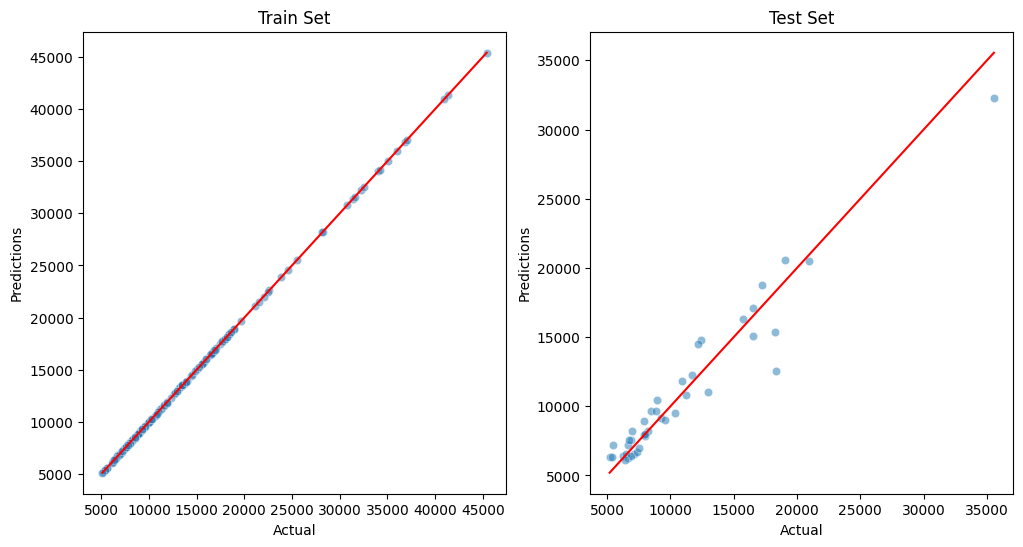

In [14]:
# code adapted from LMS
# Copilot suggestions used for comments
# call the functions set up earlier to print the train vs test set scores and display scatter plots of actual vs predicted values for both the train and test sets
regression_performance(X_train, y_train, X_test, y_test, best_pipeline)
regression_evaluation_plots(X_train, y_train, X_test, y_test, best_pipeline, alpha_scatter=0.5)

## Version 1 Conclusion

The model has overfitted on the train set as all points fall exactly on the red line and the $R^2$ score is 1.0. This may be because the hyperparameters allowed the trees to grow deep enough to memorise the training data. However, the $R^2$ score for the test set is still high, at 0.932. This means that the model successfully explains 93.2% of the variance in car prices for unseen data. Based on the MAE, the model's predictions are off on average by around $1,050.

AI Usage Note: Generative AI was used to interpret the R2 and MAE scores and used as a language tool for the above.

# Machine Learning Version 2

As our first version of the pipeline resulted in an overfitted model, we will retune the hyperparameters on our top 2 models to force them to generalise more. 

In Version 1, the decision trees grew too deep and memorised the training data (achieving a training $R^2$ score of 1). To fix this, we are running a second tuning tournament with restricted parameters:

* **`max_depth`**: We will restrict the maximum depth of the trees so they cannot grow deep enough to isolate individual data points.

* **`max_leaf_nodes`**: We will restrict the maximum number of end branches allowed, keeping the tree structure controlled and simple.

* **`min_samples_split` & `min_samples_leaf`**: We will raise these minimum sample thresholds. This forces the model to group cars together and look for broader trends rather than honing in on single-cars or anomalies, ensuring the model generalises more effectively to unseen test data.

AI Usage Note: Generative AI was used to understand the'min_samples_split' and 'min_samples_leaf' categories and used as a language tool for the above.

In [ ]:
# code adapted from LMS using generative AI

# define candidate algorithms for Version 2
models_search_v2 = {
    "ExtraTreesRegressor": ExtraTreesRegressor(random_state=101),
    "GradientBoostingRegressor": GradientBoostingRegressor(random_state=101)
}

# restricted parameter settings for Version 2
params_search_v2 = {
    "ExtraTreesRegressor": {
        'model__n_estimators': [100, 50, 150],
        'model__max_depth': [3, 5, 10],          # restrict tree depth by removing 'none'
        'model__min_samples_split': [3, 5, 10, 20, 50], # raise the threshold to reduce overfitting
        'model__min_samples_leaf': [3, 5, 10, 20, 50], # raise the threshold to reduce overfitting
    },
    "GradientBoostingRegressor": {
        'model__n_estimators': [100, 50, 140],
        'model__learning_rate': [0.1, 0.01, 0.001],
        'model__max_depth': [3, 5, 10],          # restrict tree depth by removing 'none'
        'model__min_samples_split': [3, 5, 10, 20, 50], # raise the threshold to reduce overfitting
        'model__min_samples_leaf': [3, 5, 10, 20, 50], # raise the threshold to reduce overfitting
        'model__max_leaf_nodes': [10, 20, 30], # restrict number of branches
    }
}

# run cross-validation training tournament for Version 2
search_v2 = HyperparameterOptimizationSearch(
    models=models_search_v2,
    params=params_search_v2
)
search_v2.fit(X_train, y_train, cv=3, n_jobs=-1)

# display ranked leaderboard for Version 2
grid_search_summary_v2, grid_search_pipelines_v2 = search_v2.score_summary(sort_by="mean_score")
grid_search_summary_v2


Running GridSearchCV for ExtraTreesRegressor 

Fitting 3 folds for each of 225 candidates, totalling 675 fits


c:\Users\world\Documents\CI VS Code Projects\Capstone Projects\Car-Price-Analysis-Project-3\.venv\Lib\site-packages\feature_engine\encoding\base_encoder.py:223: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(X[feature]):
c:\Users\world\Documents\CI VS Code Projects\Capstone Projects\Car-Price-Analysis-Project-3\.venv\Lib\site-packages\feature_engine\encoding\base_encoder.py:223: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(X[feature]):
c:\Users\world\Documents\CI VS Code Projects\Capstone Projects\Car-Price-Analysis-Project-3\.venv\Lib\site-packages\feature_engine\encoding\base_encoder.py:223: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) inst


Running GridSearchCV for GradientBoostingRegressor 

Fitting 3 folds for each of 2025 candidates, totalling 6075 fits


c:\Users\world\Documents\CI VS Code Projects\Capstone Projects\Car-Price-Analysis-Project-3\.venv\Lib\site-packages\feature_engine\encoding\base_encoder.py:223: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(X[feature]):
c:\Users\world\Documents\CI VS Code Projects\Capstone Projects\Car-Price-Analysis-Project-3\.venv\Lib\site-packages\feature_engine\encoding\base_encoder.py:223: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(X[feature]):
c:\Users\world\Documents\CI VS Code Projects\Capstone Projects\Car-Price-Analysis-Project-3\.venv\Lib\site-packages\feature_engine\encoding\base_encoder.py:223: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) inst

,estimator,min_score,mean_score,max_score,std_score,model__max_depth,model__min_samples_leaf,model__min_samples_split,model__n_estimators,model__learning_rate,model__max_leaf_nodes
392,GradientBoostingRegressor,0.91051,0.919212,0.926646,0.006648,3,5,3,140,0.1,30
242,GradientBoostingRegressor,0.91051,0.919212,0.926646,0.006648,3,5,3,140,0.1,10
398,GradientBoostingRegressor,0.91051,0.919212,0.926646,0.006648,3,5,10,140,0.1,30
317,GradientBoostingRegressor,0.91051,0.919212,0.926646,0.006648,3,5,3,140,0.1,20
395,GradientBoostingRegressor,0.91051,0.919212,0.926646,0.006648,3,5,5,140,0.1,30
...,...,...,...,...,...,...,...,...,...,...,...
1792,GradientBoostingRegressor,-0.006122,0.016233,0.034314,0.016782,3,50,10,50,0.001,30
2161,GradientBoostingRegressor,-0.006122,0.016233,0.034314,0.016782,10,50,3,50,0.001,20
1795,GradientBoostingRegressor,-0.006122,0.016233,0.034314,0.016782,3,50,20,50,0.001,30
1798,GradientBoostingRegressor,-0.006122,0.016233,0.034314,0.016782,3,50,50,50,0.001,30


We will save the name of the best model to a variable.

In [ ]:
# code adapted from LMS with generative AI
best_model_v2 = grid_search_summary_v2.iloc[0,0]
best_model_v2

'GradientBoostingRegressor'

We will get a list of the best parameters of the best model (Gradient Boosting Regressor).

In [ ]:
# code adapted from LMS with generative AI
grid_search_pipelines_v2[best_model_v2].best_params_

{'model__learning_rate': 0.1,
 'model__max_depth': 3,
 'model__max_leaf_nodes': 10,
 'model__min_samples_leaf': 5,
 'model__min_samples_split': 3,
 'model__n_estimators': 140}

We will save the actual model with its best parameters to a variable.

In [ ]:
# code adapted from LMS with generative AI
best_pipeline_v2 = grid_search_pipelines_v2[best_model_v2].best_estimator_
best_pipeline_v2

Pipeline(steps=[('ordinal_encoder',
                 OrdinalEncoder(encoding_method='arbitrary', unseen='encode')),
                ('scaler', StandardScaler()),
                ('model',
                 GradientBoostingRegressor(max_leaf_nodes=10,
                                           min_samples_leaf=5,
                                           min_samples_split=3,
                                           n_estimators=140,
                                           random_state=101))])

We will now evaluate this model's performance.

Model Evaluation 

* Train Set
R2 Score: 0.995
Mean Absolute Error: 457.583
Mean Squared Error: 355595.37
Root Mean Squared Error: 596.318


* Test Set
R2 Score: 0.911
Mean Absolute Error: 1121.292
Mean Squared Error: 2991643.692
Root Mean Squared Error: 1729.637




c:\Users\world\Documents\CI VS Code Projects\Capstone Projects\Car-Price-Analysis-Project-3\.venv\Lib\site-packages\feature_engine\encoding\base_encoder.py:223: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(X[feature]):
c:\Users\world\Documents\CI VS Code Projects\Capstone Projects\Car-Price-Analysis-Project-3\.venv\Lib\site-packages\feature_engine\encoding\base_encoder.py:223: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(X[feature]):
c:\Users\world\Documents\CI VS Code Projects\Capstone Projects\Car-Price-Analysis-Project-3\.venv\Lib\site-packages\feature_engine\encoding\base_encoder.py:223: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) inst

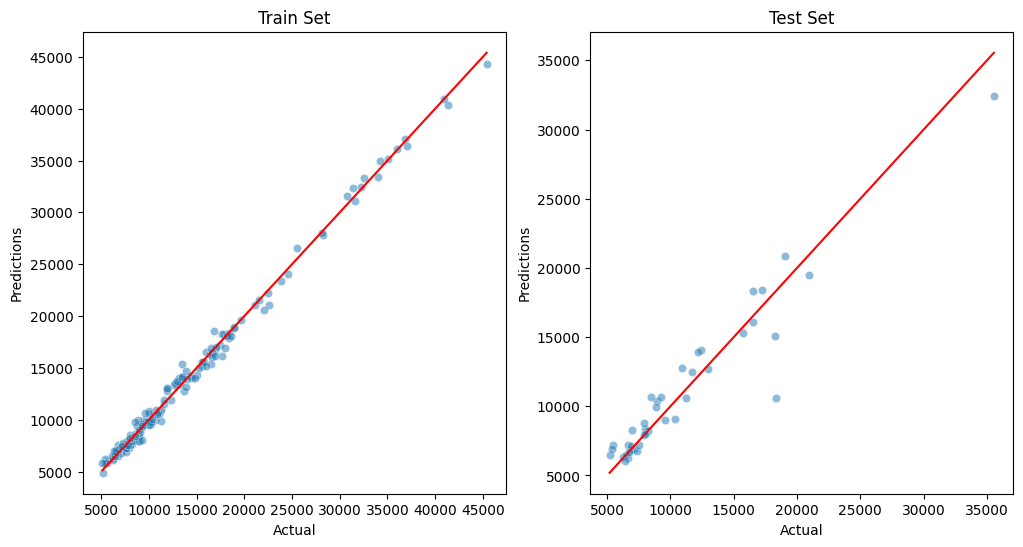

In [ ]:
# code adapted from LMS
# call the functions set up earlier to print train vs test scores and display plots
regression_performance(X_train, y_train, X_test, y_test, best_pipeline_v2)
regression_evaluation_plots(X_train, y_train, X_test, y_test, best_pipeline_v2, alpha_scatter=0.5)

## Save Actual and Predicted Test Prices 

In [ ]:
# code and comments generated by Gemini to save actual and predicted price to CSV for use in the Tableau Dashboard.

# create a DataFrame containing the test set actuals and predictions
predictions_df = pd.DataFrame({
    'Actual_Price': y_test,
    'Predicted_Price': best_pipeline_v2.predict(X_test)
})

# save it as a CSV file in your project folder
predictions_df.to_csv('model_predictions.csv', index=True)
print("Predictions saved successfully!")

Predictions saved successfully!


c:\Users\world\Documents\CI VS Code Projects\Capstone Projects\Car-Price-Analysis-Project-3\.venv\Lib\site-packages\feature_engine\encoding\base_encoder.py:223: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(X[feature]):
c:\Users\world\Documents\CI VS Code Projects\Capstone Projects\Car-Price-Analysis-Project-3\.venv\Lib\site-packages\feature_engine\encoding\base_encoder.py:223: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(X[feature]):
c:\Users\world\Documents\CI VS Code Projects\Capstone Projects\Car-Price-Analysis-Project-3\.venv\Lib\site-packages\feature_engine\encoding\base_encoder.py:223: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) inst

## Version 2 Conclusion

In Version 2, the training set $R^2$ score adjusted to 0.995. Although still high, this score shows that the model is no longer memorising every data point as it did in Version 1 ($R^2$ of 1.0). 

The Version 2 test set $R^2$ score is 0.911. While this is a minor decrease compared to Version 1, it still explains over 91% of the variance in car prices on unseen data. Although the Mean Absolute Error (MAE) increased slightly to 1,121.29, this adjustment is preferred to a highly overfitted model like Version 1.

Version 2 is a more robust and reliable model than Version 1. It successfully generalises to unseen test data rather than memorising training data points, while still maintaining high predictive performance.

AI Usage Note: Generative AI was used as a language tool for the above summary.